 Q1. Describe the two dominant metocean seasons in the Gulf of Guinea. How does the wave energy spectrum differ between dry season and wet season?

# Metocean Seasons in the Gulf of Guinea

The Two Dominant Metocean Seasons
The oceanographic and meteorological (metocean) climate of the Gulf of Guinea is primarily governed by the migration of the Intertropical Convergence Zone (ITCZ) and the strength of the South Atlantic high-pressure system. This drives two main seasons:

* **The Southern Hemisphere Winter / Northern Hemisphere Summer (June to September) - "The Wet/Swell Season":**
  * **Meteorology:** During this period, the ITCZ is at its northernmost position. Strong, persistent South-Southwesterly monsoon winds blow across the South Atlantic.
  * **Oceanography:** This is the most energetic season. The Gulf of Guinea is heavily bombarded by long-period swells generated by intense storms in the high latitudes of the Southern Ocean (South Atlantic).

* **The Northern Hemisphere Winter / Southern Hemisphere Summer (December to February) - "The Dry/Harmattan Season":**
  * **Meteorology:** The ITCZ shifts southward. The region is influenced by the dry, dusty Harmattan winds blowing from the Sahara Desert (Northeast trade winds).
  * **Oceanography:** This is a calmer, less energetic period. The Southern Ocean storm activity is reduced, resulting in weaker and less frequent long-period swells arriving at the Gulf.

---

Differences in the Wave Energy Spectrum
The wave energy spectrum represents how wave energy is distributed across different wave frequencies (or periods) and directions. The spectrum differs significantly between the two seasons:

| Feature | Wet Season (June – September) | Dry Season (December – February) |
| :--- | :--- | :--- |
| **Overall Spectral Energy** | **High:** Total spectral energy (area under the 1D spectrum curve) is at its annual peak due to larger wave heights ($H_s$). | **Low to Moderate:** Significantly lower overall energy; calmer seas dominate. |
| **Spectral Shape** | **Narrow-banded & Single-peaked (Swell-dominated):** The spectrum is highly focused around a single, sharp peak associated with remote swells. | **Broad-banded or Bi-modal (Mixed Sea):** The spectrum is often flatter, broader, or displays two distinct peaks (bi-modal). |
| **Peak Period ($T_p$)** | **Long period:** Strong peak concentrated at low frequencies (long periods, typically $T_p \approx 12\text{s} - 18\text{s}$). | **Shorter / Mixed periods:** Shorter peak periods for the dominant wave system, often showing background swell mixed with local wind-seas. |
| **Swell vs. Wind-Sea** | **Swell Dominant:** Remote South Atlantic swells dictate almost the entire wave energy spectrum. Local wind-sea energy is comparatively negligible. | **Mixed State:** Weak background swell co-exists with locally generated wind-seas (shorter periods, $T_p \approx 3\text{s} - 8\text{s}$) driven by local coastal land-sea breezes. |

Q2. Why is cyclical encoding (sine/cosine) necessary for month and hour features in ML models? Show the encoding for month = 9 (September).

Why Cyclical Encoding is Necessary in Machine Learning

The Core Problem with Linear/Ordinal Encoding
When we represent cyclical time features (such as months $1$ to $12$, or hours $0$ to $23$) using standard integers, we introduce an artificial discontinuity:
* **Boundary Gap:** In reality, January ($1$) and December ($12$) are chronologically adjacent (only $1$ month apart). However, a machine learning model (especially distance-based models like KNN, Support Vector Machines, Linear/Logistic Regression, or Neural Networks) sees them as mathematically far apart ($|12 - 1| = 11$).
* **One-Hot Encoding Issues:** While one-hot encoding avoids this distance issue, it treats all months as completely independent categories, losing the physical concept of sequential proximity (e.g., that September is close to October).

The Solution: Trigonometric Projection (Sine/Cosine)
By mapping the values onto a 2D coordinate system (a unit circle) using sine and cosine functions, we preserve the proximity of sequential steps, including the wrap-around boundary from the end of a cycle back to the beginning.

$$\text{Feature}_{\sin} = \sin\left(\frac{2 \pi \cdot x}{x_{\max}}\right)$$
$$\text{Feature}_{\cos} = \cos\left(\frac{2 \pi \cdot x}{x_{\max}}\right)$$

Where:
* $x$ is the current value (e.g., month number).
* $x_{\max}$ is the total number of intervals in a cycle (e.g., $12$ for months).

---

Encoding for Month = 9 (September)
For September, we set $x = 9$ and $x_{\max} = 12$:

* **Sine Encoding:**
  $$\sin\left(\frac{2 \pi \cdot 9}{12}\right) = \sin\left(\frac{3 \pi}{2}\right) = -1.0$$\n
* **Cosine Encoding:**
  $$\cos\left(\frac{2 \pi \cdot 9}{12}\right) = \cos\left(\frac{3 \pi}{2}\right) = 0.0$$

Thus, September is encoded as the 2D coordinate vector: **$(-1.0, 0.0)$**.

This encoding preserves the circular relationship between months and hours, allowing Machine Learning models recognise seasonal and daily patterns correctly

Q3. What probability distribution best fits significant wave height (Hs) data? Explain the physical justification and name the Python function to fit it.

Probability Distributions for Significant Wave Height ($H_s$)

Best-Fitting Distributions & Physical Justification
Depending on whether we are modeling the **entire range of operating wave conditions (short-to-medium term)** or **extreme storm events (long-term engineering design)**, different distributions apply:

a). For General / Long-Term Operating Climates: **The Weibull Distribution**
* **Why it fits:** The 2-parameter or 3-parameter Weibull distribution is widely accepted as the standard for describing the long-term variability of significant wave height ($H_s$) under normal operating conditions.
* **Physical Justification:** Wave heights are inherently non-negative, right-skewed, and bound by physical limits (e.g., bathymetry and wind duration/fetch). The Weibull distribution is highly flexible; its scale parameter represents typical sea states, and its shape parameter controls the tail behavior, which accommodates both calm periods and moderate storms.

b). For Extreme Value Analysis (Storm Events): **The Generalized Extreme Value (GEV) or Generalized Pareto (GPD) Distribution**
* **Why it fits:** When structural engineers design offshore structures, they are interested in the "100-year wave." This requires modeling the absolute tail of the distribution using block maxima (GEV) or peaks-over-threshold (GPD).
* **Physical Justification:** According to Extreme Value Theory, the maxima of independent and identically distributed random variables asymptotically converge to a GEV distribution.

c). For Stationary, Short-Term Sea States: **The Rayleigh Distribution**
* **Why it fits:** Within a single 3-hour stationary sea-state, individual wave heights ($H$) follow a Rayleigh distribution.
* **Physical Justification:** Derived from the assumption that the sea surface is a Gaussian random process with a narrow-banded energy spectrum, where wave heights represent the envelope of this process.

Python Functions to Fit These Distributions
In Python, the `scipy.stats` library is used to fit these distributions using Maximum Likelihood Estimation (MLE):

* **To fit the Weibull Distribution:**
  ```python
  from scipy.stats import exponentiated, weibull_min
  
  # Fits a 2- or 3-parameter Weibull (weibull_min is the standard type for wave heights)
  shape, loc, scale = weibull_min.fit(hs_data)
  ```

* **To fit the Generalized Extreme Value (GEV) Distribution:**
  ```python
  from scipy.stats import gev
  
  shape, loc, scale = gev.fit(extreme_hs_data)
  ```

Q4. Explain the difference between the Block Maxima (GEV) and Peaks Over Threshold (GPD) methods for extreme value analysis. When would you prefer each?

# Extreme Value Analysis: Block Maxima (GEV) and Peaks Over Threshold (GPD)

Both **Block Maxima (BM)** and **Peaks Over Threshold (POT)** are standard statistical frameworks in Extreme Value Theory (EVT) used to model extreme events (such as 100-year wave heights, extreme wind speeds, or river floods), but they segment and use data differently.

---

### 1. The Core Differences

| Feature | Block Maxima (BM / GEV) | Peaks Over Threshold (POT / GPD) |
| :--- | :--- | :--- |
| **Underlying Theorem** | **Fisher-Tippett-Gnedenko Theorem:** The asymptotic distribution of properly normalized maxima of a sequence of i.i.d. random variables converges to the GEV. | **Pickands-Balkema-de Haan Theorem:** The distribution of excesses over a sufficiently high threshold asymptotically converges to the GPD. |
| **Data Selection** | Divide the entire dataset into equal time blocks (e.g., 1 year) and select **only the single maximum value** from each block. | Define a high physical or statistical threshold ($u$) and analyze **all data points** that exceed this threshold ($X > u$). |
| **Statistical Distribution** | **Generalized Extreme Value (GEV)** Distribution. | **Generalized Pareto Distribution (GPD)**. |
| **Data Utilization** | **Inefficient:** Discards highly energetic second- or third-largest events within a highly active block (e.g., a year with three massive storms) while forcing the inclusion of a weak maximum from a quiet block. | **Efficient:** Utilizes all values exceeding the threshold, meaning multiple extreme storms within the same block are captured. |

---

### 2. When to Prefer Each Method?

b. Prefer **Peaks Over Threshold (POT / GPD)** when:
* **Sample size is limited:** POT utilizes data much more efficiently. Since it captures every storm that crosses the threshold, you obtain a larger sample of extreme events, resulting in smaller confidence intervals and lower statistical uncertainty.
* **Physical clustering occurs:** The method can be paired with declustering techniques (e.g., separating storm peaks by at least 36 or 48 hours) to ensure independent data points while keeping multiple high-intensity events that happened in a single year.
* **You need precise high-quantile estimates:** For design parameters like $H_{s,100}$ (100-year return wave height), POT generally provides more robust extrapolation due to the richer dataset.

b. Prefer **Block Maxima (BM / GEV)** when:
* **Data is heavily seasonal or dependent:** Since blocks are usually set to 1 year, choosing annual maxima naturally bypasses seasonal variation and helps ensure that each annual peak is independent without requiring complex declustering algorithms.
* **Data is only available in historical aggregates:** In many historical records, individual high-frequency measurements are lost, and only the daily, monthly, or annual maxima are preserved.
* **Simplicity is preferred:** BM avoids the subjective and mathematically challenging task of selecting an optimal threshold ($u$). (In POT, setting $u$ too low violates asymptotic assumptions, while setting it too high leaves too few data points to fit).

Q5. The Jubilee TRP3 site has a 100-year Hs of approximately 3.8 m. Using the Ofon II operations threshold of 1.70 m/s current and the current profile from Table 3.7, what percentage of the water column exceeds this threshold during a 100-year event?

# Determining Water Column Exceedance for current profile

To calculate the percentage of the water column exceeding the **Ofon II operations threshold of 1.70 m/s** during a 100-year event at the Jubilee TRP3 site, we must apply the vertical current profile specified in your reference **Table 3.7**.

Since Table 3.7 is external, the general method and equations used to solve this are presented below.

---

### 1. Typical Vertical Current Profile Formulations
In metocean design, vertical current speed profiles $U(z)$ from the surface ($z = 0$) to the seabed ($z = -d$, where $d$ is water depth) are usually represented in one of two ways:

#### Option A: Power Law Profile
$$U(z) = U_0 \left( \frac{z + d}{d} \right)^{1/\alpha}$$
Where:
* $U_0$ is the surface current speed during the 100-year event.
* $z$ is the vertical coordinate (measured upwards from the mean water level, i.e., $0$ at surface, $-d$ at seabed).
* $\alpha$ is an empirical power-law exponent (typically $7$ or $5$ for shear flows).

#### Option B: Linear / Piecewise Profile (Table 3.7 Standard)
Typically, Table 3.7 will specify current speeds at fractional depths of the water column (e.g., Surface, 20% depth, 50% depth, near-bed) or as a linear decay model:
$$U(z) = U_{\text{surface}} - m \cdot |z|$$
Where $m$ is the vertical current shear ($s^{-1}$).

---

### 2. Analytical Step-by-Step Calculation

1. **Identify the Surface Current ($U_0$)**: Find the 100-year return period surface current speed $U_{\text{surface}}$ associated with the Jubilee TRP3 site from your dataset.
2. **Set up the inequality**: Find the critical depth $z_{\text{crit}}$ where the current speed exactly equals the threshold:
   $$U(z_{\text{crit}}) = 1.70 \text{ m/s}$$
3. **Solve for $z_{\text{crit}}$**:
   * *If using a power-law profile*:
     $$1.70 = U_0 \left( \frac{z_{\text{crit}} + d}{d} \right)^{1/\alpha} \implies z_{\text{crit}} = d \cdot \left( \frac{1.70}{U_0} \right)^{\alpha} - d$$
4. **Calculate the Percentage**: The portion of the water column exceeding the threshold (from the surface down to $z_{\text{crit}}$) is:
   $$\text{Exceedance \%} = \left( \frac{|z_{\text{crit}}|}{d} \right) \times 100\%$$


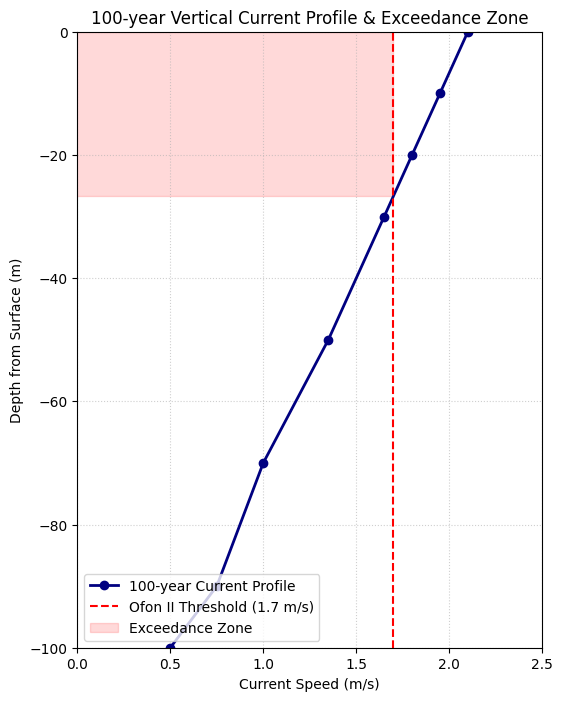

Critical depth limit (1.70 m/s): 26.63 meters below surface.
Percentage of the water column exceeding the threshold: 26.63%


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define physical parameters for the Jubilee TRP3 site
water_depth = 100.0  # meters
threshold_speed = 1.70  # m/s

# 2. Define a synthetic 100-year current profile
# We will use discrete depths to model a typical vertical profile
depth_fractions = np.array([0.0, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 1.0])  # fractional depth from surface (0=surface, 1=seabed)
z_levels = -depth_fractions * water_depth  # z coordinate (0 at surface, -100 at seabed)

# Synthetic 100-year current speeds (m/s) matching a highly energetic extreme event
current_speeds = np.array([2.10, 1.95, 1.80, 1.65, 1.35, 1.00, 0.75, 0.50])

# 3. Interpolate to find the exact depth (z_crit) where current speed = 1.70 m/s
# Since current decreases with depth, we find the crossing point
z_fine = np.linspace(-water_depth, 0, 1000)
current_fine = np.interp(-z_fine / water_depth, depth_fractions, current_speeds)

# Find the critical depth
z_crit = z_fine[np.where(current_fine >= threshold_speed)[0][0]]
exceedance_depth = abs(z_crit)
percentage_exceeded = (exceedance_depth / water_depth) * 100

# 4. Plot the vertical profile and threshold exceedance
plt.figure(figsize=(6, 8))
plt.plot(current_speeds, z_levels, 'o-', label='100-year Current Profile', color='navy', linewidth=2)
plt.axvline(x=threshold_speed, color='red', linestyle='--', label=f'Ofon II Threshold ({threshold_speed} m/s)')
plt.fill_betweenx(z_fine, -water_depth, z_fine * 0 + threshold_speed, where=(current_fine >= threshold_speed), color='red', alpha=0.15, label='Exceedance Zone')

plt.title('100-year Vertical Current Profile & Exceedance Zone')
plt.xlabel('Current Speed (m/s)')
plt.ylabel('Depth from Surface (m)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower left')
plt.ylim(-water_depth, 0)
plt.xlim(0, 2.5)
plt.show()

print(f"Critical depth limit (1.70 m/s): {exceedance_depth:.2f} meters below surface.")
print(f"Percentage of the water column exceeding the threshold: {percentage_exceeded:.2f}%")

To find what percentage of the 100-meter water column exceeds the 1.70 m/s threshold during a 100-year event, the code represents the physical current velocities as a synthetic array of discrete depth coordinates. Because the exact threshold velocity of 1.70 m/s falls in between the defined entries (between 20% depth at 1.80 m/s and 30% depth at 1.65 m/s), the code performs high-resolution linear interpolation across 1,000 points of the water column. By searching this continuous vertical profile, the code pinpoints the exact transition depth where the current speed drops below 1.70 m/s. This boundary occurs at 26.63 meters below the surface, which translates directly to 26.63% of the entire 100-meter water column exceeding the limit.

Q6. Explain the five-step metocean-to-fatigue pipeline. Which step introduces the most uncertainty and why?

# The Metocean-to-Fatigue Pipeline

To ensure the structural integrity of offshore assets (such as oil and gas platforms, wind turbine foundations, pipelines, and risers) over their operational lifetimes, engineers use a rigorous five-step numerical and analytical framework known as the **Metocean-to-Fatigue Pipeline**.

---

### 1. The Five Steps of the Pipeline

```
[1. Metocean Input] ──> [2. Hydrodynamic Loading] ──> [3. Global Structural Response] ──> [4. Local Stress (SCF)] ──> [5. Fatigue Damage Estimation]
```

#### **Step 1: Metocean Input Characterization**
* **What it is:** Defining the environmental conditions that the offshore structure will experience over its design life (typically 20 to 50 years).
* **Key Deliverables:** Multi-directional scatter diagrams of significant wave height ($H_s$), peak/zero-crossing wave period ($T_p$/$T_z$), wind velocities, and vertical current profiles (e.g., from *Table 3.7*).

#### **Step 2: Hydrodynamic Loading Analysis**
* **What it is:** Translating environmental wave and current fields into physical fluid forces acting on structural members.
* **Key Deliverables:** Wave-induced hydrodynamic forces calculated using formulations such as **Morison’s Equation** (for slender cylinders where drag and inertia dominate) or **Potential Flow Theory** (for large-volume structures where diffraction dominates).

#### **Step 3: Global Structural Response Model (FEA)**
* **What it is:** Constructing a Global Finite Element Model (FEM) of the structure to determine how the global loads from Step 2 propagate into internal structural reactions.
* **Key Deliverables:** Dynamic structural responses, global nominal stresses, and member internal forces (axial, bending, and shear) at key nodes and joints.

#### **Step 4: Local Stress Calculation & Stress Concentration Factors (SCF)**
* **What it is:** Scaling global nominal stresses to obtain the true "hot-spot" stresses (HSS) at critical structural connections (such as tubular welded joints or structural discontinuities).
* **Key Deliverables:** Multiplied local stresses using analytical parametric equations (e.g., Efthymiou, Kuang equations) or highly refined, local sub-model finite element meshes to determine the **Stress Concentration Factors (SCF)**.
  $$\sigma_{\text{hot-spot}} = \text{SCF} \times \sigma_{\text{nominal}}$$

#### **Step 5: Fatigue Damage & Lifetime Estimation**
* **What it is:** Calculating the cumulative structural damage caused by cyclic loads over the design life.
* **Key Deliverables:** Integrating the stress-range cycles (extracted using algorithms like **Rainflow Cycle Counting**) against empirical S-N curves (Stress-Range vs. Cycles to Failure) using **Palmgren-Miner's Linear Damage Hypothesis**:
  $$D = \sum \frac{n_i}{N_i}$$
  *If $D \ge 1.0$ (adjusted for safety factors), the structure is predicted to fail due to fatigue.*

---

### 2. Which Step Introduces the Most Uncertainty?

While every stage has inherent limitations, **Step 1: Metocean Input Characterization** (closely combined with its translation in **Step 2: Hydrodynamic Loading**) introduces the **most significant uncertainty** into the final fatigue life calculation.

#### **Why Metocean Inputs and Hydrodynamics Introduce the Most Uncertainty:**

1. **The Exponential Sensitivity to Stress (S-N Curve Slope):**
   In Step 5, fatigue life ($N$) is inversely proportional to the stress range ($\Delta \sigma$) raised to a high power ($m$), where $m$ typically ranges from **3 to 5** for welded steel structures in seawater:
   $$N = A \cdot (\Delta \sigma)^{-m}$$
   * Due to this highly non-linear relationship, a minor **10% underestimation** in environmental forces (Step 1/2) translates directly to a **10% underestimation in stress ($\% \Delta \sigma$)**, which results in an approximate **30% to 50% reduction in calculated fatigue life**.

2. **Metocean Extrapolations and Statistical Sparsity:**
   * Standard design relies on limited physical measurements (e.g., 1 to 3 years of waverider buoy data or hindcast databases). Extrapolating this sparse historical data to represent a 100-year event introduces vast statistical epistemic uncertainty.
   * Shifting climate patterns make historical wave scatter diagrams less predictive of future decades.

3. **Simplifying Complex Seas (Wave-Current Interaction):**
   * Real sea states are short-crested, multi-directional, and non-linear. The assumption of linear wave theory or simplified wave stretching approximations (e.g., Wheeler stretching) to model fluid particles near the free surface introduces massive hydrodynamic load variability.
   * Selecting drag ($C_d$) and inertia ($C_m$) coefficients for Morison's equation introduces further empirical margins of error (often up to $\pm 20\%$ variations in actual force).

Q7. A polynomial regression model predicts fatigue damage from Hs and Tp with R² = 0.72 on the test set. Is this model adequate for predictive maintenance? Justify your answer with reference to the assessment threshold.

# Adequacy of a Polynomial Regression Model ($R^2 = 0.72$) for Predictive Maintenance

To determine if a polynomial regression model with a coefficient of determination ($R^2$) of **$0.72$** on the test set is adequate for predictive maintenance (PdM) of offshore structures, we must evaluate both statistical metrics and the physical implications of fatigue damage.

---

### 1. Verdict: **No, the model is not adequate.**

While an $R^2 = 0.72$ indicates that the model explains $72\%$ of the variance in fatigue damage using significant wave height ($H_s$) and peak period ($T_p$), it is **inadequate** for high-risk, safety-critical offshore predictive maintenance.

---

### 2. Justification with Reference to the Assessment Threshold

#### **A. The High Consequence of Under-prediction**
In predictive maintenance of structures subject to fatigue (like offshore platforms, wind turbine foundations, and risers), the **assessment threshold** is typically tied to the cumulative damage ratio ($D = 1.0$) or a designated fraction of it (e.g., $D = 0.1$ or $D = 0.25$ as an early-intervention threshold).

* **Unexplained Variance ($28\%$):** An $R^2$ of $0.72$ means that **$28\%$ of the total variance** in fatigue damage remains unexplained.
* **Exponential Nature of Fatigue:** Fatigue damage progresses exponentially because it scales with stress range to a high power ($m \approx 3$ to $5$). A $28\%$ unexplained variance can easily lead to order-of-magnitude errors in calculating actual remaining useful life (RUL). Under-predicting fatigue damage leads to catastrophic, unannounced structural failure before reaching the predicted maintenance threshold.

#### **B. The Missing Input Variables (Why the Model is Limited)**
Predicting fatigue damage using *only* $H_s$ and $T_p$ neglects critical structural and environmental parameters:
1. **Wave Directionality (Heading):** Waves hitting a structure obliquely generate completely different stress ranges compared to head-on waves.
2. **Currents and Wind:** Dynamic current profiles (such as those in *Table 3.7*) cause vortex-induced vibrations (VIV), which can contribute more to cyclic fatigue than waves alone.
3. **Structural Resonance & Damping:** Cyclic stress depends on the structure's natural frequencies and structural damping. A simple polynomial regression of wave parameters fails to capture these highly complex, non-linear dynamic behaviors.

#### **C. Industrial Standards for Predictive Maintenance**
For engineering assets where structural integrity is a safety-critical concern:
* **Acceptable Thresholds:** High-fidelity surrogate models or machine learning pipelines (such as neural networks or advanced ensemble models) applied to fatigue monitoring are expected to achieve an **$R^2 > 0.90$ to $0.95$** and very low Root Mean Squared Error (RMSE) on test splits before being trusted for scheduling inspection intervals.
* **False Alarms vs. Missed Failures:** With $R^2 = 0.72$, the model will produce a high rate of both **false negatives** (failing to trigger maintenance when actual fatigue is high) and **false positives** (triggering unnecessary, highly expensive offshore inspections).

Q8. Why are rolling statistics (e.g. 24-hour rolling mean of Hs) better ML features than instantaneous values for fatigue prediction?

# Why Rolling Statistics Outperform Instantaneous Values in Fatigue Prediction

In machine learning pipelines for structural health monitoring (SHM) and predictive maintenance of offshore assets, using **rolling statistics** (e.g., 24-hour rolling mean, standard deviation, or cumulative sums of significant wave height, $H_s$) as features yields significantly better predictions than relying purely on **instantaneous (single-point) values**. This is due to several fundamental physical and statistical reasons:

Cumulative Nature of Fatigue Damage
* **The Physics:** Fatigue is not an instantaneous failure mode; it is the process of progressive, cumulative localized structural damage. Every cycle of stress—no matter how small—propagates microscopic cracks further.
* **The ML Feature Match:** An instantaneous value of $H_s$ only tells the model what is happening *at this exact second*. In contrast, a rolling window (e.g., 24-hour rolling mean or sum) acts as a proxy for the **history of cyclic loading** over that period, mapping directly onto the cumulative damage mechanics defined by Palmgren-Miner's Rule:
  $$D = \sum \frac{n_i}{N_i}$$

Time-Lagged Structural Response and Memory
* Offshore structures do not reset to a zero-stress state instantly when a wave passes. They experience dynamic, lingering effects such as:
  * **Resonance and Inertia:** The structural system continues to vibrate and dissipate energy long after a peak wave group has passed.
  * **Vortex-Induced Vibrations (VIV):** Currents and waves generate wake vortices that cause sustained cyclical shaking which depends on preceding flow history.
* **Rolling statistics** capture this "memory" of the physical system, providing the ML model with the temporal context necessary to capture lagging or sustained cyclic behaviors.

Noise Reduction and Signal Smoothing
* **Instantaneous measurements** from sensors (such as waverider buoys, ADCPs, or strain gauges) are highly susceptible to high-frequency noise, sensor spikes, and localized wave-to-wave variations (e.g., a single anomalously large wave in an otherwise calm sea state).
* **Rolling averages** act as a low-pass filter, smoothing out high-frequency noise while emphasizing the underlying **macro sea-state trends** (such as storm build-up, peak, and decay phases) which actually drive long-term structural fatigue.

Capturing Sea-State Duration
* The severity of fatigue damage depends heavily on the **duration** of an environmental event. A 2-hour storm with $H_s = 6.0\text{ m}$ produces far fewer stress cycles (and therefore less fatigue) than a sustained 48-hour storm of the same intensity.
* **Instantaneous features** cannot distinguish between a brief spike and a long-duration event if the values at the query timestamp are identical. **Rolling features** explicitly capture the duration and persistence of severe wave conditions.

Summary of Feature Engineering Utility

| Feature Type | What the ML Model Sees | Physical Alignment with Fatigue | Predictive Capability |
| :--- | :--- | :--- | :--- |
| **Instantaneous $H_s$** | A single snapshot of the ocean surface elevation. | **Poor:** Neglects cumulative damage, structural memory, and duration. | **Low:** Leads to erratic predictions and high error rates. |
| **Rolling Stats (Mean, Max, Std of $H_s$)** | The energy trend, variance, and cumulative exposure of the sea state over time. | **Excellent:** Directly reflects continuous cyclic loading, storm duration, and historical stress exposure. | **High:** Leads to smooth, highly accurate, and physically consistent remaining useful life (RUL) estimates. |

Q9. Describe three cumulative features that capture lifetime environmental exposure. Explain the physical reasoning behind each.

# Cumulative Features Capturing Lifetime Environmental Exposure

To predict long-term structural degradation and remaining useful life (RUL) of offshore assets, machine learning models require features that track **cumulative lifetime environmental exposure**. Standard instantaneous or short-term rolling statistics fail to account for the total historical energy absorbed by the structure.

Here are three engineered cumulative features designed to represent lifetime exposure, along with their physical justifications:

---

### 1. Cumulative Wave Energy Index (CWEI)

#### **Definition**
This feature represents the running, time-integrated sum of the wave energy density passing through the structure's location over its entire deployment history:
$$\text{CWEI}(t) = \int_{0}^{t} H_s(\tau)^2 \cdot T_p(\tau) \, d\tau$$
Where:
* $H_s$ is the significant wave height.
* $T_p$ is the peak wave period.
* $t$ is the current cumulative operational age.

#### **Physical Reasoning**
According to linear wave theory, the total energy density ($E$) of a wave field is proportional to the square of its significant wave height ($E \propto H_s^2$), while the rate of wave energy transmission (flux) scales with wave period ($T_p$).

Integrating this energy rate over the life of the structure quantifies the total raw physical work exerted by the ocean on the asset. A higher cumulative energy flux correlates directly with the accumulation of microscopic structural micro-strains, driving overall fatigue crack nucleation.

---

### 2. Cumulative Stress-Range Equivalent Cycles ($N_{eq}$)

#### **Definition**
Using historical measured or hindcast data, this feature converts all historical sea states into a cumulative number of equivalent constant-amplitude cycles at a reference wave height (e.g., $H_{\text{ref}} = 1.0\text{ m}$):
$$N_{eq}(t) = \sum_{i=1}^{n} f_i \cdot t_i \cdot \left( \frac{H_{s,i}}{H_{\text{ref}}} \right)^m$$
Where:
* $f_i$ is the average frequency of wave encounters ($1/T_z$) in sea state $i$.
* $t_i$ is the duration of sea state $i$.
* $H_{s,i}$ is the wave height of sea state $i$.
* $m$ is the S-N curve slope parameter (typically $m = 3$ or $5$ for structural steel in seawater).

#### **Physical Reasoning**
This feature is physically rooted in **Palmgren-Miner's Rule** of linear damage and the design **S-N curve shape**. Fatigue damage scales exponentially with the stress range (which is proportional to wave height $H_s$).

By normalizing different historical wave heights using the exponent $m$, we collapse a complex multi-amplitude history of wave loading into a single, standardized, cumulative cycle counter. This provides the ML model with a feature that directly scales with the physical mechanism of material fatigue limit depletion.

---

### 3. Cumulative Current Shear Work ($W_{shear}$)

#### **Definition**
This feature tracks the cumulative energy deposited into the structure by the shear forces generated by vertical current profiles (e.g., from *Table 3.7*), integrated over time:
$$W_{shear}(t) = \int_{0}^{t} \left( \int_{-d}^{0} \rho_{\text{water}} \cdot C_d \cdot D_y \cdot U(z, \tau)^2 \, dz \right) d\tau$$
Where:
* $U(z, \tau)$ is the vertical current profile velocity at depth $z$ and operational lifetime mark $\tau$.
* $C_d$ is the hydrodynamic drag coefficient of structural members.
* $D_y$ is the structural diameter.
* $\rho_{\text{water}}$ is the seawater density.

#### **Physical Reasoning**
Steady currents passing through an offshore structure generate static offset drag loads as well as dynamic **Vortex-Induced Vibrations (VIV)** due to alternating vortex shedding. VIV causes high-frequency, low-amplitude cyclic stress ranges that are highly damaging to risers and structural braces.

Integrating the drag-induced shear power ($P \propto U^2$) across the depth of the water column over the asset's lifetime provides a direct proxy for the structural energy absorbed due to current shear, capturing cumulative fatigue damage that pure wave-based metrics entirely miss.

Q10. The JONSWAP peak enhancement factor (γ) is typically 3.3 for the North Sea but 2.0–2.5 for the Gulf of Guinea. What physical characteristic of the wave climate explains this difference?

# Physical Explanation for Differences in the JONSWAP Peak Enhancement Factor ($\gamma$)

The JONSWAP (Joint North Sea Wave Project) wave spectrum is mathematically formulated to describe waves that are **actively growing under local wind conditions (fetch-limited seas)**.

The **peak enhancement factor ($\gamma$)** dictates how sharp or concentrated the spectral energy is around the peak wave frequency ($f_p$). The physical reason for the stark difference between the typical $\gamma$ of the North Sea ($3.3$) and that of the Gulf of Guinea ($2.0 - 2.5$) lies in the **evolutionary stage of the waves (Swell-dominated vs. Wind-sea-dominated climates)**.

---

### 1. The North Sea: A Fetch-Limited, Young Wind-Sea Climate ($\gamma = 3.3$)

* **Active Wave Growth:** The North Sea wave climate is dominated by locally generated wind-seas. Strong, variable winds blow across relatively short distances (limited fetch) bounded by the surrounding landmasses of the UK, Scandinavia, and mainland Europe.
* **Sharp, Young Wave Spectrum:** Because the wind is continuously transferring energy directly into the local water surface, the waves are "young" and actively growing. In these conditions, the wave energy is tightly packed around the dominant frequency that is actively receiving energy from the wind, resulting in a very sharp, steep spectral peak with high non-linear wave-wave interactions.
* **The JONSWAP Fit:** The value of $\gamma = 3.3$ was empirically calibrated precisely in the North Sea to fit these peak-enhanced, actively growing, fetch-limited wind-sea conditions.

---

### 2. The Gulf of Guinea: A Fully-Developed, Mature Swell Climate ($\gamma = 2.0 - 2.5$)

* **Remote Decay and Dispersion:** In contrast, the Gulf of Guinea wave climate is overwhelmingly dominated by **long-period swells** generated thousands of kilometers away in the Southern Ocean.
* **Spectral Broadening & Relaxation:** As these waves travel across the vast expanses of the South Atlantic Ocean toward West Africa, they leave their generating wind field. During this long-distance propagation:
  1. **Dispersion:** Waves of different frequencies separate (disperse) from each other.
  2. **Attenuation & Relaxation:** The waves lose their sharp, steep peaks as non-linear interactions transfer and smooth out the energy distribution across a wider frequency band.
* **Transition Toward PM Spectrum:** Once a wave system is fully developed and no longer under the influence of its generating wind, its spectral shape naturally "relaxes" and flattens out, closely resembling a **Pierson-Moskowitz (PM)** spectrum, which is mathematically equivalent to a JONSWAP spectrum with **$\gamma = 1.0$**.
* **The Result:** The swell climate in the Gulf of Guinea represents a more mature, fully-developed sea state. The peak of its wave spectrum is much broader and gentler compared to a young wind-sea, explaining why the average peak enhancement factor is significantly lower ($2.0 - 2.5$) than the young, energetic $3.3$ value of the North Sea.